# Day 40: Customer Segmentation & Service Recommendation System

**Dataset:** a simulated Veda Technology customer dataset (5,000 customers), generated in this
notebook

This notebook is the first of four days in the Customer Segmentation & Service Recommendation
System project. It creates the simulated customer dataset, builds a data preprocessing
pipeline, and analyzes customer behavior. The next days use this data to find customer
segments with K-Means (Day 41), describe the segments and build the service recommendation
logic (Day 42), and finish with a segment dashboard and business recommendations (Day 43).

## 1. Import Libraries

In [1]:
import sqlite3
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)

# Folders for the raw and cleaned customer data
DATA_DIR = Path("../datasets/veda_customers")
RAW_DIR = DATA_DIR / "raw"
CLEAN_DIR = DATA_DIR / "cleaned"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)

## 2. Simulated Veda Technology Customer Dataset

The project asks for **synthetic or public** customer data, and no real Veda Technology
customer data is used here. The dataset has one row per customer (5,000 customers who signed
up between October 1, 2025 and September 30, 2026) and 16 columns:

| Column | Meaning |
|---|---|
| `customer_id` | Unique customer ID |
| `signup_date` | Date the customer signed up |
| `customer_type` | Student, Working Professional, Small Business, Startup, Enterprise, or Educational Institution |
| `region` | Region of the customer |
| `acquisition_channel` | Channel that brought the customer to Veda Technology |
| `primary_interest` | Main area of interest: Internships, Training Programs, IT Services, or Digital Services |
| `website_visits` | Website visits since signing up |
| `avg_session_minutes` | Average length of a website session, in minutes |
| `pages_per_visit` | Average number of pages viewed per visit |
| `email_open_rate_pct` | Share of Veda Technology emails the customer opened |
| `days_since_last_activity` | Days since the customer last visited the website, opened an email, or contacted Veda |
| `service_inquiries` | Number of service inquiries made |
| `support_tickets` | Number of support tickets raised |
| `purchases` | Number of purchases (training programs, internships, or services) |
| `total_spend_inr` | Total spending in INR |
| `satisfaction_rating` | Survey rating from 1 to 5 (many customers never answer the survey) |

A fixed random seed (`42`) makes the data reproducible. Each customer is generated from one
of four hidden behavior patterns, similar to the example segments in the project hints:
highly engaged learners, occasional visitors, new customers, and service-focused business
clients. The pattern decides how much a customer visits, opens emails, asks about services,
and spends, but it is **not saved in the data**, so the segmentation on Day 41 has to find
the groups from behavior alone. Because the groups are built in, any finding in this project
reflects the assumptions I chose and not the real customers of Veda Technology.

The table is first generated cleanly, then deliberately made messy (duplicate rows, missing
values, inconsistent labels, mixed date formats, spending stored as text, and impossible
numbers) and saved as a **raw** file, so the preprocessing pipeline has real work to do.

**Settings and the behavior pattern of each hidden group**

In [2]:
rng = np.random.default_rng(42)

N_CUSTOMERS = 5000
START, END = pd.Timestamp("2025-10-01"), pd.Timestamp("2026-09-30")
REFERENCE_DATE = END  # the "today" used for tenure and recency
ALL_DAYS = pd.date_range(START, END, freq="D")

SEGMENTS = ["Engaged Learner", "Occasional Visitor", "New Customer", "Service-Focused Client"]
SEGMENT_SHARES = [0.30, 0.31, 0.19, 0.20]

CUSTOMER_TYPES = ["Student", "Working Professional", "Small Business", "Startup", "Enterprise", "Educational Institution"]
INTERESTS = ["Internships", "Training Programs", "IT Services", "Digital Services"]
REGIONS = ["South India", "North India", "West India", "East India", "International"]
CHANNELS = ["Organic Search", "Social Media", "Direct", "Paid Ads", "Referral", "Email"]

# Which categories each hidden group is likely to have (the order follows the lists above)
CATEGORY_PROBS = {
    "customer_type": (CUSTOMER_TYPES, {
        "Engaged Learner": [0.62, 0.30, 0.03, 0.03, 0.00, 0.02],
        "Occasional Visitor": [0.38, 0.30, 0.14, 0.10, 0.03, 0.05],
        "New Customer": [0.42, 0.26, 0.14, 0.10, 0.02, 0.06],
        "Service-Focused Client": [0.02, 0.04, 0.36, 0.28, 0.18, 0.12],
    }),
    "primary_interest": (INTERESTS, {
        "Engaged Learner": [0.40, 0.50, 0.04, 0.06],
        "Occasional Visitor": [0.25, 0.30, 0.20, 0.25],
        "New Customer": [0.30, 0.30, 0.18, 0.22],
        "Service-Focused Client": [0.02, 0.04, 0.54, 0.40],
    }),
    "acquisition_channel": (CHANNELS, {
        "Engaged Learner": [0.25, 0.20, 0.12, 0.10, 0.18, 0.15],
        "Occasional Visitor": [0.30, 0.30, 0.15, 0.17, 0.04, 0.04],
        "New Customer": [0.25, 0.27, 0.13, 0.20, 0.08, 0.07],
        "Service-Focused Client": [0.22, 0.06, 0.20, 0.10, 0.30, 0.12],
    }),
}

# Behavior of each hidden group: visits, session length, pages, email opens, how long since the
# last activity, inquiries, tickets, how many customers buy, how many orders, and order value
SEGMENT_PARAMS = pd.DataFrame({
    "Engaged Learner": dict(visit_shape=6.0, visit_scale=3.3, session_mean=9.5, session_sd=2.5, pages_mean=6.5, pages_sd=1.8,
                            email_mean=58, email_sd=14, idle_offset=0, idle_scale=6, inquiry_rate=0.6, ticket_rate=0.4,
                            buyer_prob=0.90, extra_orders=1.3, order_median=9000, order_sigma=0.45, rating_base=4.3),
    "Occasional Visitor": dict(visit_shape=2.5, visit_scale=1.2, session_mean=2.8, session_sd=1.2, pages_mean=2.4, pages_sd=0.9,
                               email_mean=14, email_sd=9, idle_offset=40, idle_scale=60, inquiry_rate=0.25, ticket_rate=0.2,
                               buyer_prob=0.25, extra_orders=0.3, order_median=4000, order_sigma=0.60, rating_base=3.6),
    "New Customer": dict(visit_shape=4.0, visit_scale=1.5, session_mean=4.5, session_sd=1.8, pages_mean=3.6, pages_sd=1.2,
                         email_mean=32, email_sd=14, idle_offset=0, idle_scale=8, inquiry_rate=0.4, ticket_rate=0.3,
                         buyer_prob=0.45, extra_orders=0.2, order_median=5500, order_sigma=0.55, rating_base=4.0),
    "Service-Focused Client": dict(visit_shape=3.0, visit_scale=2.5, session_mean=7.0, session_sd=2.5, pages_mean=5.2, pages_sd=1.6,
                                   email_mean=26, email_sd=13, idle_offset=0, idle_scale=20, inquiry_rate=5.6, ticket_rate=2.2,
                                   buyer_prob=0.85, extra_orders=2.0, order_median=48000, order_sigma=0.80, rating_base=3.9),
}).T
SEGMENT_PARAMS

,visit_shape,visit_scale,session_mean,session_sd,pages_mean,pages_sd,email_mean,email_sd,idle_offset,idle_scale,inquiry_rate,ticket_rate,buyer_prob,extra_orders,order_median,order_sigma,rating_base
Engaged Learner,6.0,3.3,9.5,2.5,6.5,1.8,58.0,14.0,0.0,6.0,0.60,0.4,0.90,1.3,9000.0,0.45,4.3
Occasional Visitor,2.5,1.2,2.8,1.2,2.4,0.9,14.0,9.0,40.0,60.0,0.25,0.2,0.25,0.3,4000.0,0.60,3.6
New Customer,4.0,1.5,4.5,1.8,3.6,1.2,32.0,14.0,0.0,8.0,0.40,0.3,0.45,0.2,5500.0,0.55,4.0
Service-Focused Client,3.0,2.5,7.0,2.5,5.2,1.6,26.0,13.0,0.0,20.0,5.60,2.2,0.85,2.0,48000.0,0.80,3.9


**The function that generates the customers**

Every customer gets a hidden group first, and all of the customer's numbers are then drawn
from that group's pattern. A few rules keep the data realistic: new customers all joined in
the last 60 days, nobody can be inactive for longer than they have been a customer, spending
is zero when there are no purchases, and only some customers answer the satisfaction survey.

In [3]:
def categorical_by_segment(segment, options, probs_by_segment):
    values = np.empty(len(segment), dtype=object)
    for name, probs in probs_by_segment.items():
        rows = segment == name
        values[rows] = rng.choice(options, size=rows.sum(), p=probs)
    return values


def generate_customers(n=N_CUSTOMERS):
    segment = rng.choice(SEGMENTS, size=n, p=SEGMENT_SHARES)
    p = SEGMENT_PARAMS.loc[segment].reset_index(drop=True)

    def col(name):
        return p[name].to_numpy()

    # Sign-up dates: a growth trend and busier weekdays; new customers all joined in the last 60 days
    position = np.arange(len(ALL_DAYS)) / len(ALL_DAYS)
    weights = (1 + 0.35 * position) * np.where(ALL_DAYS.dayofweek < 5, 1.15, 0.75)
    signup = pd.Series(pd.to_datetime(rng.choice(ALL_DAYS.to_numpy(), size=n, p=weights / weights.sum())))
    new = segment == "New Customer"
    signup.loc[new] = pd.to_datetime(rng.choice(ALL_DAYS[-60:].to_numpy(), size=new.sum())).to_numpy()
    tenure = (REFERENCE_DATE - signup).dt.days.to_numpy()

    # Engagement
    visits = rng.poisson(rng.gamma(col("visit_shape"), col("visit_scale")))
    session = np.clip(rng.normal(col("session_mean"), col("session_sd")), 0.5, 60).round(1)
    pages = np.clip(rng.normal(col("pages_mean"), col("pages_sd")), 1, 30).round(1)
    email_open = np.clip(rng.normal(col("email_mean"), col("email_sd")), 0, 100).round(1)
    idle = np.minimum(np.floor(col("idle_offset") + rng.exponential(col("idle_scale"))), tenure).astype(int)

    # Inquiries and support (gamma-Poisson counts, so some customers ask far more than others)
    inquiries = rng.poisson(rng.gamma(2.0, col("inquiry_rate") / 2.0))
    tickets = rng.poisson(rng.gamma(2.0, col("ticket_rate") / 2.0))

    # Purchases and spending
    buyer = rng.random(n) < col("buyer_prob")
    orders = np.where(buyer, 1 + rng.poisson(col("extra_orders")), 0)
    order_value = col("order_median") * np.exp(rng.normal(0, col("order_sigma")))
    spend = np.where(orders > 0, np.maximum(np.round(orders * order_value, -2), 500), 0)

    # Satisfaction survey: more tickets lower the rating, and buyers answer more often
    rating_mean = col("rating_base") - 0.18 * tickets + 0.15 * (orders > 0)
    rating = np.clip(np.round(rng.normal(rating_mean, 0.8)), 1, 5)
    rating = np.where(rng.random(n) < np.where(orders > 0, 0.70, 0.30), rating, np.nan)

    df = pd.DataFrame({
        "signup_date": signup,
        "customer_type": categorical_by_segment(segment, *CATEGORY_PROBS["customer_type"]),
        "region": rng.choice(REGIONS, size=n, p=[0.34, 0.24, 0.20, 0.12, 0.10]),
        "acquisition_channel": categorical_by_segment(segment, *CATEGORY_PROBS["acquisition_channel"]),
        "primary_interest": categorical_by_segment(segment, *CATEGORY_PROBS["primary_interest"]),
        "website_visits": visits, "avg_session_minutes": session, "pages_per_visit": pages,
        "email_open_rate_pct": email_open, "days_since_last_activity": idle,
        "service_inquiries": inquiries, "support_tickets": tickets, "purchases": orders,
        "total_spend_inr": spend, "satisfaction_rating": rating,
        "true_segment": segment,  # only used to check the simulation, never saved
    })
    df = df.sort_values("signup_date", kind="stable").reset_index(drop=True)
    df.insert(0, "customer_id", [f"C{i + 1:05d}" for i in range(len(df))])
    return df


customers_true = generate_customers()
customers_true.drop(columns="true_segment").head()

,customer_id,signup_date,customer_type,region,acquisition_channel,primary_interest,website_visits,avg_session_minutes,pages_per_visit,email_open_rate_pct,days_since_last_activity,service_inquiries,support_tickets,purchases,total_spend_inr,satisfaction_rating
0,C00001,2025-10-01,Student,International,Organic Search,Training Programs,38,7.7,7.4,59.6,13,2,0,3,20500.0,NaN
1,C00002,2025-10-01,Enterprise,South India,Direct,Training Programs,5,8.7,3.9,13.2,5,10,2,2,41400.0,4.0
2,C00003,2025-10-01,Enterprise,North India,Email,IT Services,16,7.2,3.7,45.8,20,21,1,2,129300.0,4.0
3,C00004,2025-10-01,Enterprise,West India,Referral,IT Services,15,3.5,5.2,6.7,8,0,0,3,112400.0,3.0
4,C00005,2025-10-01,Student,West India,Organic Search,Internships,22,10.2,7.1,60.8,5,0,3,2,15700.0,4.0


**Making the table messy**

The same kinds of problems that real customer data has are added on purpose: different
spellings of the same label, impossible numbers, values that contradict each other, missing
values, dates in two formats, spending typed as text (for example `₹12,500`), and duplicate
rows. The original clean table stays in memory, which later makes it possible to check the
cleaning against the truth.

In [4]:
LABEL_VARIANTS = {
    "customer_type": {
        "Student": [" student", "STUDENT", "Stud."],
        "Working Professional": ["working professional", "Professional", "Working Prof."],
        "Small Business": ["small business", "SMB", "Small Biz"],
        "Startup": ["start-up", "Start up", "STARTUP"],
        "Enterprise": ["enterprise ", "Enterprise Co.", "Corporate"],
        "Educational Institution": ["Edu Institution", "College/University", "School"],
    },
    "region": {
        "South India": ["south", "S. India", "SOUTH INDIA"], "North India": ["north", "N. India", "north india "],
        "West India": ["west", "W. India"], "East India": ["east", "E. India"],
        "International": ["Intl", "Abroad", "Overseas"],
    },
    "acquisition_channel": {
        "Organic Search": ["google organic", "SEO", "organic"], "Social Media": ["Facebook", "Instagram", "FB", "social"],
        "Direct": ["direct traffic", "DIRECT"], "Paid Ads": ["Google Ads", "PPC", "paid"],
        "Referral": ["referral ", "Referred", "Friend referral"], "Email": ["E-mail", "email campaign", "newsletter"],
    },
    "primary_interest": {
        "Internships": ["internship", "Intern", "INTERNSHIPS"], "Training Programs": ["training", "Courses", "Training Program"],
        "IT Services": ["IT", "it services", "IT Service"], "Digital Services": ["digital", "Digital Marketing", "Web & Digital"],
    },
}


def add_label_noise(values, variants, frac):
    values = np.array(values, dtype=object)
    for i in np.flatnonzero(rng.random(len(values)) < frac):
        options = variants.get(values[i])
        if options:
            values[i] = options[rng.integers(len(options))]
    return values


def make_messy(clean):
    df = clean.drop(columns="true_segment").copy()
    n = len(df)
    tenure = (REFERENCE_DATE - df["signup_date"]).dt.days.to_numpy()
    for column in ["website_visits", "days_since_last_activity", "service_inquiries", "support_tickets", "total_spend_inr"]:
        df[column] = df[column].astype(float)

    def corrupt(column, frac, make_values, only=None):
        rows = rng.random(n) < frac
        if only is not None:
            rows &= only
        df.loc[rows, column] = make_values(rows)

    # 1. Impossible numbers and values that contradict each other
    corrupt("avg_session_minutes", 0.004, lambda r: -rng.uniform(1, 30, r.sum()).round(1))
    corrupt("avg_session_minutes", 0.002, lambda r: rng.uniform(400, 900, r.sum()).round(1))
    corrupt("email_open_rate_pct", 0.005, lambda r: rng.uniform(101, 250, r.sum()).round(1))
    corrupt("days_since_last_activity", 0.004, lambda r: -rng.integers(1, 40, r.sum()))
    corrupt("days_since_last_activity", 0.004, lambda r: tenure[r] + rng.integers(5, 60, r.sum()))  # before sign-up
    corrupt("website_visits", 0.002, lambda r: rng.integers(400, 3000, r.sum()))
    corrupt("pages_per_visit", 0.003, lambda r: rng.choice([0, 95, 150], r.sum()))
    corrupt("total_spend_inr", 0.003, lambda r: -np.round(rng.uniform(500, 20000, r.sum()), -2))
    corrupt("total_spend_inr", 0.003, lambda r: rng.integers(5, 40, r.sum()) * 500, only=(df["purchases"] == 0).to_numpy())
    corrupt("satisfaction_rating", 0.005, lambda r: rng.choice([0, 6, 9, 10], r.sum()), only=df["satisfaction_rating"].notna().to_numpy())

    # 2. Inconsistent labels
    for column, variants in LABEL_VARIANTS.items():
        df[column] = add_label_noise(df[column].to_numpy(dtype=object), variants, 0.12)

    # 3. Missing values
    missing_fractions = {
        "website_visits": 0.015, "avg_session_minutes": 0.03, "pages_per_visit": 0.03, "email_open_rate_pct": 0.035,
        "days_since_last_activity": 0.015, "service_inquiries": 0.01, "support_tickets": 0.01, "total_spend_inr": 0.015,
        "customer_type": 0.02, "region": 0.03, "acquisition_channel": 0.015, "primary_interest": 0.02,
    }
    for column, frac in missing_fractions.items():
        df.loc[rng.random(n) < frac, column] = np.nan

    # 4. Dates in two formats (2026-03-05 and 05-03-2026)
    text = df["signup_date"].dt.strftime("%Y-%m-%d").to_numpy(dtype=object)
    swap = rng.random(n) < 0.03
    text[swap] = df.loc[swap, "signup_date"].dt.strftime("%d-%m-%Y").to_numpy()
    df["signup_date"] = text

    # 5. Spending typed as text
    spend = df["total_spend_inr"].to_numpy(dtype=object)
    for i in np.flatnonzero((rng.random(n) < 0.025) & df["total_spend_inr"].gt(0).to_numpy()):
        value = int(spend[i])
        spend[i] = [f"\u20b9{value:,}", f"Rs. {value:,}", f"{value} INR"][rng.integers(3)]
    df["total_spend_inr"] = spend

    # 6. Duplicate rows
    duplicates = df.iloc[rng.choice(n, size=int(n * 0.02), replace=False)]
    return pd.concat([df, duplicates]).sort_index(kind="stable").reset_index(drop=True)


raw_customers_made = make_messy(customers_true)
raw_customers_made.to_csv(RAW_DIR / "customers_raw.csv", index=False)

print("Clean customers:", len(customers_true), "| raw rows saved:", len(raw_customers_made))
print("Raw file:", RAW_DIR / "customers_raw.csv")
raw_customers_made.head(8)

Clean customers: 5000 | raw rows saved: 5100
Raw file: ../datasets/veda_customers/raw/customers_raw.csv


,customer_id,signup_date,customer_type,region,acquisition_channel,primary_interest,website_visits,avg_session_minutes,pages_per_visit,email_open_rate_pct,days_since_last_activity,service_inquiries,support_tickets,purchases,total_spend_inr,satisfaction_rating
0,C00001,2025-10-01,Student,International,Organic Search,Training Programs,38.0,7.7,7.4,59.6,13.0,2.0,0.0,3,20500.0,NaN
1,C00002,2025-10-01,Enterprise,South India,Direct,Training Programs,5.0,8.7,3.9,13.2,5.0,10.0,2.0,2,41400.0,4.0
2,C00003,2025-10-01,enterprise,North India,Email,IT Services,16.0,7.2,3.7,45.8,20.0,21.0,1.0,2,129300.0,4.0
3,C00004,2025-10-01,Enterprise,West India,referral,it services,15.0,3.5,NaN,6.7,8.0,0.0,0.0,3,112400.0,3.0
4,C00005,2025-10-01,Student,West India,Organic Search,Internships,22.0,10.2,7.1,60.8,5.0,0.0,3.0,2,15700.0,4.0
5,C00006,2025-10-01,Working Professional,North India,Organic Search,Internships,14.0,5.6,7.9,69.1,10.0,1.0,0.0,2,34100.0,5.0
6,C00006,2025-10-01,Working Professional,North India,Organic Search,Internships,14.0,5.6,7.9,69.1,10.0,1.0,0.0,2,34100.0,5.0
7,C00007,2025-10-01,Working Professional,International,Organic Search,Digital Services,6.0,1.6,2.3,36.9,209.0,0.0,0.0,1,10400.0,4.0


## 3. Data Quality Check on the Raw Data

The raw file is loaded back from disk, and the problems are measured before anything is
changed.

In [5]:
raw_customers = pd.read_csv(RAW_DIR / "customers_raw.csv")

quality = pd.Series({
    "rows": len(raw_customers),
    "duplicate_rows": int(raw_customers.duplicated().sum()),
    "missing_cells": int(raw_customers.isna().sum().sum()),
    "dates_not_in_iso_format": int((~raw_customers["signup_date"].astype(str).str.match(r"^\d{4}-\d{2}-\d{2}$")).sum()),
    "spend_values_stored_as_text": int(pd.to_numeric(raw_customers["total_spend_inr"], errors="coerce").isna().sum()
                                       - raw_customers["total_spend_inr"].isna().sum()),
}).to_frame("raw data")
quality

,raw data
rows,5100
duplicate_rows,100
missing_cells,3606
dates_not_in_iso_format,147
spend_values_stored_as_text,57


**Missing values by column (the satisfaction survey is expected to have many gaps)**

In [6]:
missing = raw_customers.isna().sum()
missing[missing > 0].sort_values(ascending=False).to_frame("missing values")

,missing values
satisfaction_rating,2298
email_open_rate_pct,182
region,175
avg_session_minutes,161
pages_per_visit,161
customer_type,123
primary_interest,100
website_visits,89
total_spend_inr,79
days_since_last_activity,68


**Inconsistent labels: every label column has more distinct values than it should**

In [7]:
label_options = {"customer_type": CUSTOMER_TYPES, "region": REGIONS, "acquisition_channel": CHANNELS, "primary_interest": INTERESTS}

pd.DataFrame({
    "distinct_values_found": {col: raw_customers[col].nunique(dropna=True) for col in label_options},
    "distinct_values_expected": {col: len(options) for col, options in label_options.items()},
})

,distinct_values_found,distinct_values_expected
customer_type,24,6
region,18,5
acquisition_channel,24,6
primary_interest,16,4


In [8]:
raw_customers["customer_type"].value_counts(dropna=False)

customer_type
Student                    1764
Working Professional       1083
Small Business              632
Startup                     474
Enterprise                  223
Educational Institution     214
NaN                         123
STUDENT                      85
 student                     69
Stud.                        67
Professional                 53
working professional         48
Working Prof.                45
Small Biz                    34
start-up                     26
STARTUP                      24
small business               22
SMB                          21
Start up                     19
School                       15
enterprise                   13
Corporate                    13
Edu Institution              12
Enterprise Co.               11
College/University           10
Name: count, dtype: int64

**Invalid numbers: values that cannot be real**

In [9]:
spend_numeric = pd.to_numeric(raw_customers["total_spend_inr"], errors="coerce")

pd.Series({
    "Negative session lengths": (raw_customers["avg_session_minutes"] < 0).sum(),
    "Session lengths over 2 hours": (raw_customers["avg_session_minutes"] > 120).sum(),
    "Email open rates above 100%": (raw_customers["email_open_rate_pct"] > 100).sum(),
    "Negative days since last activity": (raw_customers["days_since_last_activity"] < 0).sum(),
    "Website visits above 300": (raw_customers["website_visits"] > 300).sum(),
    "Pages per visit of 0 or above 40": ((raw_customers["pages_per_visit"] < 1) | (raw_customers["pages_per_visit"] > 40)).sum(),
    "Negative total spend": (spend_numeric < 0).sum(),
    "Satisfaction ratings outside 1 to 5": ((raw_customers["satisfaction_rating"] < 1) | (raw_customers["satisfaction_rating"] > 5)).sum(),
    "Spend recorded for customers with no purchases": ((raw_customers["purchases"] == 0) & (spend_numeric > 0)).sum(),
}).to_frame("rows")

,rows
Negative session lengths,18
Session lengths over 2 hours,8
Email open rates above 100%,28
Negative days since last activity,15
Website visits above 300,8
Pages per visit of 0 or above 40,13
Negative total spend,15
Satisfaction ratings outside 1 to 5,9
Spend recorded for customers with no purchases,4


**Observation:** the raw file has 5,100 rows for 5,000 customers (100 duplicate rows), 3,606 empty cells (2,298 of them are the satisfaction survey, where gaps are expected, and 1,308 are real gaps in other columns), 147 dates written day-first (`05-03-2026`) instead of year-first, and 57 spending values typed as text (like `₹12,500`). The label columns have far more distinct values than they should (24 customer types instead of 6, 18 regions instead of 5, 24 channels instead of 6, and 16 interests instead of 4), because of spellings like `SMB`, `STUDENT`, `FB`, and `Intl`. The numbers also contain impossible values (such as negative session lengths, email open rates above 100%, and negative spending) and values that contradict each other (spending recorded for customers who never bought). The pipeline in the next section handles each of these problems.

## 4. Data Cleaning and Preprocessing Pipeline

All of the cleaning is done by **one pipeline function**, driven by a short specification (which column is the ID, which
are dates, which hold numbers, which are labels, what range is valid for each number, and which gaps should be filled). The steps
follow a fixed order, so the result is the same every time the notebook is run:

1. Remove duplicate rows (and duplicate IDs)
2. Parse the dates, which come in two formats
3. Convert numbers that were typed as text (`₹12,500`, `Rs. 12,500`, `12500 INR`) into numbers
4. Standardize the labels: trim spaces, ignore capitalization, and map known variants to the correct label
5. Set impossible numbers to missing
6. Apply logic rules: a customer cannot have been inactive for longer than they have been a customer, and a customer with no purchases cannot have spent money
7. Fill the remaining gaps (labels become `Unknown`, numbers get the median of the customer type, and spending follows its own rule)
8. Convert whole-number columns back to integers

**The cleaning helper functions**

In [10]:
def parse_mixed_dates(series):
    # Dates come in two formats: 2026-03-05 and 05-03-2026
    text = series.astype("string")
    iso = pd.to_datetime(text, format="%Y-%m-%d", errors="coerce")
    day_first = pd.to_datetime(text, format="%d-%m-%Y", errors="coerce")
    return iso.fillna(day_first)


def standardize_labels(series, aliases, canonical):
    lookup = {label.lower(): label for label in canonical}
    lookup.update({alias.lower(): label for alias, label in aliases.items()})
    cleaned = series.astype("string").str.strip().str.replace(r"\s+", " ", regex=True).str.lower()
    return cleaned.map(lookup)


def clean_customers(raw_table, spec):
    df = raw_table.copy()
    log = {"rows_raw": len(df)}

    # 1. Duplicates
    df = df.drop_duplicates().drop_duplicates(subset=spec["id"])
    log["duplicates_removed"] = log["rows_raw"] - len(df)

    # 2. Dates (rows whose date cannot be read are dropped)
    for col in spec["dates"]:
        df[col] = parse_mixed_dates(df[col])
    before = len(df)
    df = df.dropna(subset=spec["dates"])
    log["bad_dates_dropped"] = before - len(df)

    # 3. Numbers typed as text
    converted = 0
    for col in spec["numbers"]:
        text = df[col].astype("string")
        direct = pd.to_numeric(text, errors="coerce")
        stripped = pd.to_numeric(text.str.replace(r"(?i)rs\.?|inr|\u20b9|,|\s", "", regex=True), errors="coerce")
        converted += int((direct.isna() & text.notna() & stripped.notna()).sum())
        df[col] = direct.fillna(stripped).astype(float)
    log["text_numbers_converted"] = converted

    # 4. Labels
    relabeled = unknown = 0
    for col, (canonical, aliases) in spec["labels"].items():
        original = df[col].astype("string")
        standardized = standardize_labels(original, aliases, canonical)
        relabeled += int(((standardized != original) & standardized.notna()).sum())
        unknown += int(standardized.isna().sum())
        df[col] = standardized.fillna("Unknown")
    log["labels_standardized"] = relabeled
    log["labels_set_to_unknown"] = unknown

    # 5. Impossible numbers become missing
    invalid = 0
    for col, (low, high) in spec["ranges"].items():
        out_of_range = (df[col] < low) | (df[col] > high)
        invalid += int(out_of_range.sum())
        df.loc[out_of_range, col] = np.nan
    log["impossible_numbers_set_to_missing"] = invalid

    # 6. Logic rules
    tenure = (REFERENCE_DATE - df["signup_date"]).dt.days
    activity_before_signup = df["days_since_last_activity"] > tenure
    spend_without_purchase = (df["purchases"] == 0) & (df["total_spend_inr"] > 0)
    df.loc[activity_before_signup, "days_since_last_activity"] = np.nan
    df.loc[spend_without_purchase, "total_spend_inr"] = np.nan
    log["logic_violations_set_to_missing"] = int(activity_before_signup.sum() + spend_without_purchase.sum())

    # 7. Fill the remaining gaps (satisfaction_rating is left as it is, on purpose)
    filled = 0
    for col in spec["impute"]:
        gaps = df[col].isna()
        group_median = df.groupby("customer_type")[col].transform("median")
        df.loc[gaps, col] = group_median[gaps]
        filled += int(gaps.sum())

    # Spending: no purchases means no spending, and a buyer gets the median spending of buyers of the same type
    gaps = df["total_spend_inr"].isna()
    df.loc[gaps & (df["purchases"] == 0), "total_spend_inr"] = 0
    buyers = df["purchases"] > 0
    type_median = df[buyers].groupby("customer_type")["total_spend_inr"].median()
    buyer_gaps = df["total_spend_inr"].isna()
    fallback = df.loc[buyers, "total_spend_inr"].median()
    df.loc[buyer_gaps, "total_spend_inr"] = df.loc[buyer_gaps, "customer_type"].map(type_median).fillna(fallback)
    filled += int(gaps.sum())
    df["days_since_last_activity"] = np.minimum(df["days_since_last_activity"], tenure)
    log["numbers_imputed"] = filled

    # 8. Types and rounding
    for col, digits in spec["decimals"].items():
        df[col] = df[col].round(digits)
    df["total_spend_inr"] = df["total_spend_inr"].round(-2)
    for col in spec["integers"]:
        df[col] = df[col].round().astype(int)
    df["satisfaction_rating"] = df["satisfaction_rating"].astype("Int64")

    log["rows_clean"] = len(df)
    return df.reset_index(drop=True), log


def validate(df, spec):
    tenure = (REFERENCE_DATE - df["signup_date"]).dt.days
    checks = {
        "duplicate_rows": int(df.duplicated().sum()),
        "duplicate_ids": int(df[spec["id"]].duplicated().sum()),
        "dates_outside_study_period": int(((df["signup_date"] < START) | (df["signup_date"] > END)).sum()),
        "labels_not_recognized": int(sum((~df[col].isin(canonical + ["Unknown"])).sum() for col, (canonical, _) in spec["labels"].items())),
        "missing_values_outside_survey": int(df.drop(columns="satisfaction_rating").isna().sum().sum()),
        "numbers_out_of_range": int(sum(((df[col] < low) | (df[col] > high)).sum() for col, (low, high) in spec["ranges"].items())),
        "inactive_longer_than_customer": int((df["days_since_last_activity"] > tenure).sum()),
        "spend_without_purchases": int(((df["purchases"] == 0) & (df["total_spend_inr"] > 0)).sum()),
        "purchases_without_spend": int(((df["purchases"] > 0) & (df["total_spend_inr"] == 0)).sum()),
    }
    return pd.Series(checks)

**The specification**

The label variants below were found by inspecting the distinct values in each column.
Differences in capitalization and extra spaces are handled automatically, so only the
genuinely different spellings (like `SMB` or `Google Ads`) need to be listed.

In [11]:
SPEC = {
    "id": "customer_id",
    "dates": ["signup_date"],
    "numbers": ["website_visits", "avg_session_minutes", "pages_per_visit", "email_open_rate_pct", "days_since_last_activity",
                "service_inquiries", "support_tickets", "purchases", "total_spend_inr", "satisfaction_rating"],
    "labels": {
        "customer_type": (CUSTOMER_TYPES, {
            "stud.": "Student", "professional": "Working Professional", "working prof.": "Working Professional",
            "smb": "Small Business", "small biz": "Small Business", "start-up": "Startup", "start up": "Startup",
            "enterprise co.": "Enterprise", "corporate": "Enterprise", "edu institution": "Educational Institution",
            "college/university": "Educational Institution", "school": "Educational Institution"}),
        "region": (REGIONS, {
            "south": "South India", "s. india": "South India", "north": "North India", "n. india": "North India",
            "west": "West India", "w. india": "West India", "east": "East India", "e. india": "East India",
            "intl": "International", "abroad": "International", "overseas": "International"}),
        "acquisition_channel": (CHANNELS, {
            "google organic": "Organic Search", "seo": "Organic Search", "organic": "Organic Search",
            "facebook": "Social Media", "instagram": "Social Media", "fb": "Social Media", "social": "Social Media",
            "direct traffic": "Direct", "google ads": "Paid Ads", "ppc": "Paid Ads", "paid": "Paid Ads",
            "referred": "Referral", "friend referral": "Referral",
            "e-mail": "Email", "email campaign": "Email", "newsletter": "Email"}),
        "primary_interest": (INTERESTS, {
            "internship": "Internships", "intern": "Internships", "training": "Training Programs", "courses": "Training Programs",
            "training program": "Training Programs", "it": "IT Services", "it service": "IT Services",
            "digital": "Digital Services", "digital marketing": "Digital Services", "web & digital": "Digital Services"}),
    },
    "ranges": {
        "website_visits": (0, 300), "avg_session_minutes": (0, 120), "pages_per_visit": (1, 40), "email_open_rate_pct": (0, 100),
        "days_since_last_activity": (0, 365), "service_inquiries": (0, 60), "support_tickets": (0, 30), "purchases": (0, 50),
        "total_spend_inr": (0, 10_000_000), "satisfaction_rating": (1, 5),
    },
    "impute": ["website_visits", "avg_session_minutes", "pages_per_visit", "email_open_rate_pct", "days_since_last_activity",
               "service_inquiries", "support_tickets"],
    "integers": ["website_visits", "days_since_last_activity", "service_inquiries", "support_tickets", "purchases", "total_spend_inr"],
    "decimals": {"avg_session_minutes": 1, "pages_per_visit": 1, "email_open_rate_pct": 1},
}

**Running the pipeline**

One column is left with gaps **on purpose**: `satisfaction_rating`. A customer who did not
answer the survey has no rating, and filling it would invent an opinion. Ratings outside 1 to 5
are set to missing too, but they are not filled either.

In [12]:
clean_customers_df, cleaning_log = clean_customers(raw_customers, SPEC)
pd.Series(cleaning_log).to_frame("rows or values")

,rows or values
rows_raw,5100
duplicates_removed,100
bad_dates_dropped,0
text_numbers_converted,56
labels_standardized,2305
labels_set_to_unknown,449
impossible_numbers_set_to_missing,114
logic_violations_set_to_missing,25
numbers_imputed,959
rows_clean,5000


**Validation checks on the cleaned table (every value should be 0)**

In [13]:
validate(clean_customers_df, SPEC).to_frame("problems found")

,problems found
duplicate_rows,0
duplicate_ids,0
dates_outside_study_period,0
labels_not_recognized,0
missing_values_outside_survey,0
numbers_out_of_range,0
inactive_longer_than_customer,0
spend_without_purchases,0
purchases_without_spend,0


**Checking the pipeline against the original clean table**

Because the data was simulated, the original clean table is still in memory, which makes it
possible to check the pipeline against the truth, something that is not possible with real
data. The cleaned table should hold exactly the same customers, dates, and labels as the
original, and its numbers should stay close to the original ones.

In [14]:
original = customers_true.set_index("customer_id")
cleaned = clean_customers_df.set_index("customer_id")

same_customers = set(original.index) == set(cleaned.index)
original = original.loc[cleaned.index]
same_dates = bool((original["signup_date"] == cleaned["signup_date"]).all())

label_check = {}
for col in SPEC["labels"]:
    known = cleaned[col] != "Unknown"
    label_check[col] = {
        "labels_that_were_unknown": int((~known).sum()),
        "labels_matching_the_original_pct": round((cleaned.loc[known, col] == original.loc[known, col]).mean() * 100, 2),
    }

print("Same customers as the original:", same_customers, "| same sign-up dates:", same_dates)
pd.DataFrame(label_check).T.astype({"labels_that_were_unknown": int})

Same customers as the original: True | same sign-up dates: True


,labels_that_were_unknown,labels_matching_the_original_pct
customer_type,119,100.0
region,168,100.0
acquisition_channel,65,100.0
primary_interest,97,100.0


In [15]:
numeric_check = {}
for col in SPEC["numbers"]:
    before, after = original[col].astype(float), cleaned[col].astype(float)
    same = ((before == after) | (before.isna() & after.isna())).mean() * 100
    numeric_check[col] = {
        "original_mean": round(before.mean(), 2), "cleaned_mean": round(after.mean(), 2),
        "cells_identical_to_original_pct": round(same, 1),
    }

pd.DataFrame(numeric_check).T

,original_mean,cleaned_mean,cells_identical_to_original_pct
website_visits,9.75,9.68,98.1
avg_session_minutes,6.00,5.98,96.4
pages_per_visit,4.41,4.39,96.7
email_open_rate_pct,33.18,33.13,95.9
days_since_last_activity,31.09,30.69,98.1
service_inquiries,1.44,1.43,99.6
support_tickets,0.67,0.66,99.5
purchases,1.32,1.32,100.0
total_spend_inr,41707.82,41253.76,98.9
satisfaction_rating,3.93,3.93,99.8


In [16]:
# Save the cleaned customer table for the next days of the project
clean_customers_df.to_csv(CLEAN_DIR / "customers_cleaned.csv", index=False)

print("Cleaned table saved to:", CLEAN_DIR / "customers_cleaned.csv")
print("Rows:", len(clean_customers_df), "| columns:", clean_customers_df.shape[1])
clean_customers_df.head()

Cleaned table saved to: ../datasets/veda_customers/cleaned/customers_cleaned.csv
Rows: 5000 | columns: 16


,customer_id,signup_date,customer_type,region,acquisition_channel,primary_interest,website_visits,avg_session_minutes,pages_per_visit,email_open_rate_pct,days_since_last_activity,service_inquiries,support_tickets,purchases,total_spend_inr,satisfaction_rating
0,C00001,2025-10-01,Student,International,Organic Search,Training Programs,38,7.7,7.4,59.6,13,2,0,3,20500,<NA>
1,C00002,2025-10-01,Enterprise,South India,Direct,Training Programs,5,8.7,3.9,13.2,5,10,2,2,41400,4
2,C00003,2025-10-01,Enterprise,North India,Email,IT Services,16,7.2,3.7,45.8,20,21,1,2,129300,4
3,C00004,2025-10-01,Enterprise,West India,Referral,IT Services,15,3.5,4.4,6.7,8,0,0,3,112400,3
4,C00005,2025-10-01,Student,West India,Organic Search,Internships,22,10.2,7.1,60.8,5,0,3,2,15700,4


**Observation:** the pipeline turned 5,100 raw rows into 5,000 clean customers. It removed 100 duplicate rows, converted 56 spending values from text to numbers, standardized 2,305 inconsistent labels, set 114 impossible numbers and 25 contradictory values to missing, and filled 959 numeric gaps (the gaps in the raw data plus the values it had just set to missing) with the median of the customer type, with spending following its own rule (no purchases means no spending). The 449 values marked `Unknown` are not spellings the pipeline failed to recognize: they are the blank labels of the raw data (464 before the duplicates were removed). `satisfaction_rating` keeps its gaps on purpose, because 45% of customers did not answer the survey. All the validation checks pass, and the comparison with the original table confirms that the cleaned table holds the same 5,000 customers and sign-up dates, that every recognized label matches the original, and that the column means stay within about 1.3% of the original ones (for example, the average spend moved from INR 41,708 to INR 41,254). Between 96% and 100% of the cells in each numeric column are identical to the original, something only a simulation can show. On real data the same checks would show that the data is internally consistent, but not that it is correct.

## 5. Customer Behavior Analysis

The analysis uses the cleaned table. A few helper columns are added for the analysis only
(`tenure_days`, `signup_month`, and `is_buyer`) and are not part of the saved dataset, because
feature engineering is the job of Day 41.

**Key figures for the customer base**

In [17]:
customers = clean_customers_df.copy()
customers["tenure_days"] = (REFERENCE_DATE - customers["signup_date"]).dt.days
customers["signup_month"] = customers["signup_date"].dt.to_period("M")
customers["is_buyer"] = customers["purchases"] > 0
buyers = customers[customers["is_buyer"]]

customer_kpis = pd.Series({
    "Customers": len(customers),
    "Joined in the last 60 days (%)": (customers["tenure_days"] <= 60).mean() * 100,
    "Active in the last 30 days (%)": (customers["days_since_last_activity"] <= 30).mean() * 100,
    "Inactive for over 90 days (%)": (customers["days_since_last_activity"] > 90).mean() * 100,
    "Customers who bought (%)": customers["is_buyer"].mean() * 100,
    "Total spend (INR million)": customers["total_spend_inr"].sum() / 1e6,
    "Average spend per customer (INR)": customers["total_spend_inr"].mean(),
    "Median spend per customer (INR)": customers["total_spend_inr"].median(),
    "Average spend per buyer (INR)": buyers["total_spend_inr"].mean(),
    "Average website visits": customers["website_visits"].mean(),
    "Average email open rate (%)": customers["email_open_rate_pct"].mean(),
    "Average service inquiries": customers["service_inquiries"].mean(),
    "Average support tickets": customers["support_tickets"].mean(),
    "Survey response rate (%)": customers["satisfaction_rating"].notna().mean() * 100,
    "Average satisfaction (1 to 5)": customers["satisfaction_rating"].mean(),
}).round(2)

customer_kpis.to_frame("value")

,value
Customers,5000.00
Joined in the last 60 days (%),33.06
Active in the last 30 days (%),68.56
Inactive for over 90 days (%),9.86
Customers who bought (%),60.26
Total spend (INR million),206.27
Average spend per customer (INR),41253.76
Median spend per customer (INR),5900.00
Average spend per buyer (INR),68459.61
Average website visits,9.68


**Who the customers are**

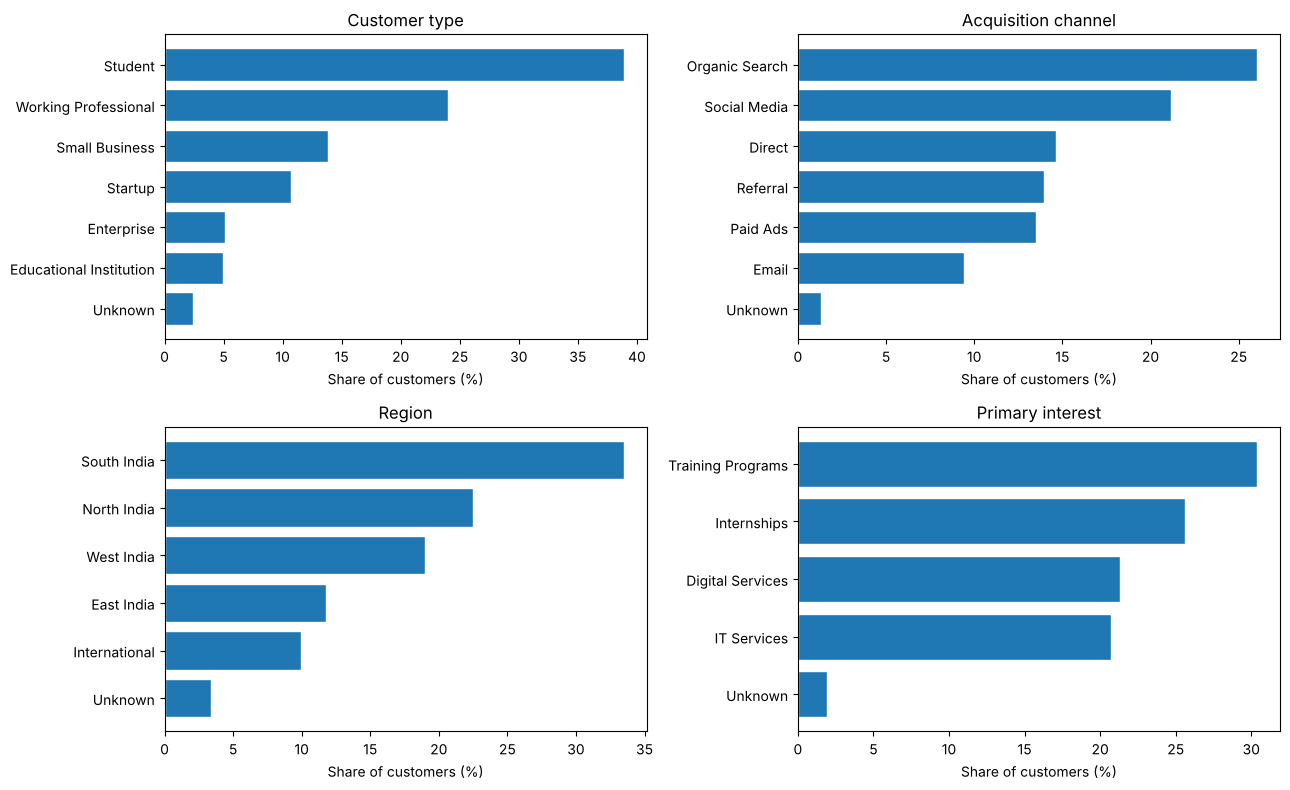

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
panels = [("customer_type", "Customer type"), ("acquisition_channel", "Acquisition channel"),
          ("region", "Region"), ("primary_interest", "Primary interest")]

for ax, (col, title) in zip(axes.flat, panels):
    shares = customers[col].value_counts(normalize=True).mul(100).sort_values()
    ax.barh(shares.index, shares.values, edgecolor="white")
    ax.set_title(title)
    ax.set_xlabel("Share of customers (%)")

plt.tight_layout()
plt.show()

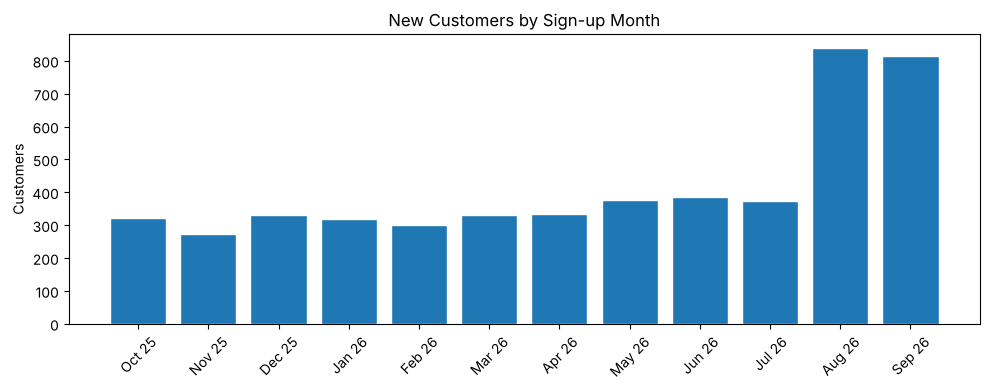

signup_month,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
customers,322,272,332,319,301,331,334,376,386,374,838,815


In [19]:
signups = customers.groupby("signup_month").size()
signup_labels = signups.index.strftime("%b %y")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(signup_labels, signups.values, edgecolor="white")
ax.set_title("New Customers by Sign-up Month")
ax.set_ylabel("Customers")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

signups.to_frame("customers").T

**Engagement: how customers use the website and emails**

The dashed line shows the median.

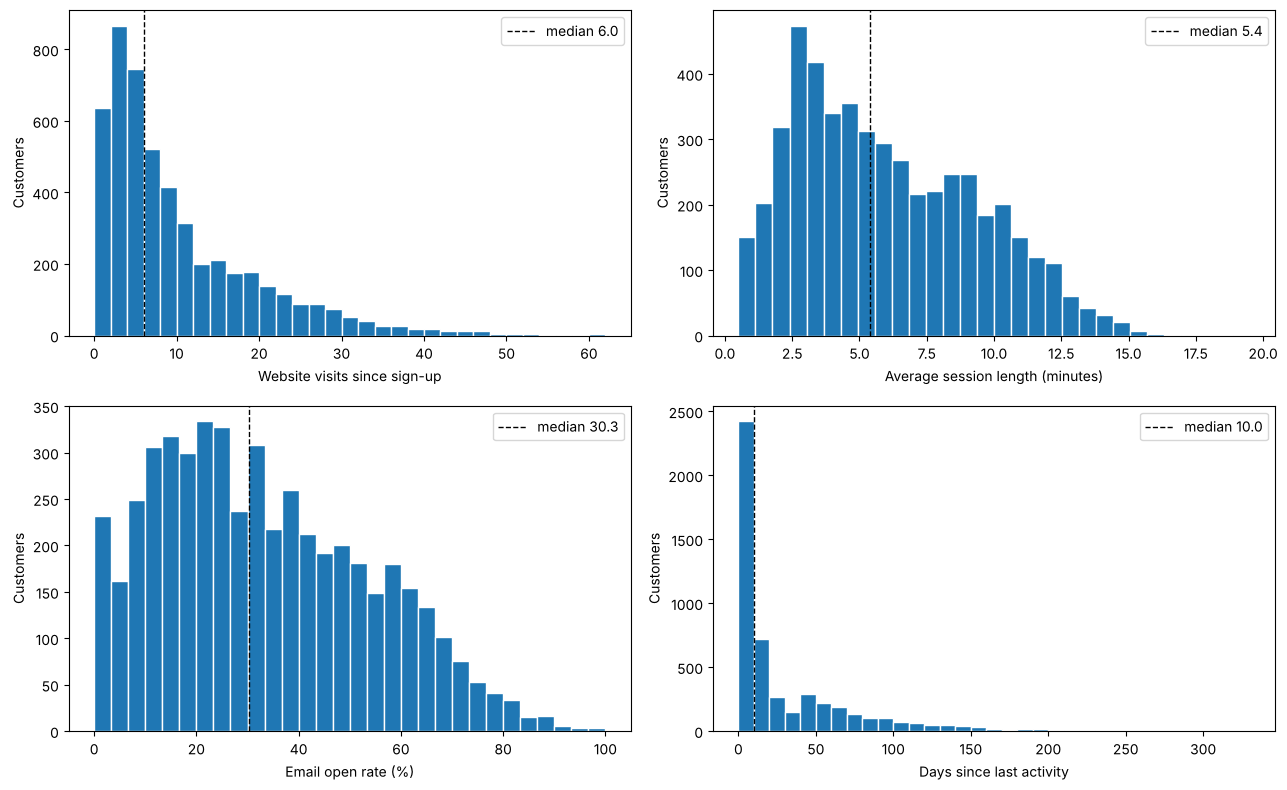

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
panels = [("website_visits", "Website visits since sign-up", list(range(0, 64, 2))), ("avg_session_minutes", "Average session length (minutes)", 30),
          ("email_open_rate_pct", "Email open rate (%)", 30), ("days_since_last_activity", "Days since last activity", list(range(0, 340, 10)))]

for ax, (col, label, bins) in zip(axes.flat, panels):
    ax.hist(customers[col], bins=bins, edgecolor="white")
    median = customers[col].median()
    ax.axvline(median, color="black", linestyle="--", linewidth=1, label=f"median {median:.1f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Customers")
    ax.legend()

plt.tight_layout()
plt.show()

In [21]:
profile_by_type = customers.groupby("customer_type").agg(
    customers=("customer_id", "count"), avg_visits=("website_visits", "mean"), avg_session_min=("avg_session_minutes", "mean"),
    avg_pages=("pages_per_visit", "mean"), avg_email_open_pct=("email_open_rate_pct", "mean"),
    avg_days_inactive=("days_since_last_activity", "mean"), avg_inquiries=("service_inquiries", "mean"),
    buyers_pct=("is_buyer", "mean"), avg_spend_inr=("total_spend_inr", "mean"),
)
profile_by_type["buyers_pct"] = profile_by_type["buyers_pct"] * 100
profile_by_type.round(1).sort_values("avg_spend_inr", ascending=False)

,customers,avg_visits,avg_session_min,avg_pages,avg_email_open_pct,avg_days_inactive,avg_inquiries,buyers_pct,avg_spend_inr
customer_type,,,,,,,,,
Enterprise,256,6.8,5.9,4.4,23.0,31.4,4.1,69.1,120957.4
Small Business,694,6.7,5.6,4.2,26.3,29.7,3.0,63.1,101750.1
Educational Institution,248,7.2,5.7,4.3,29.1,30.0,2.2,58.5,78990.3
Startup,537,6.6,5.4,4.1,25.4,33.2,2.8,62.0,76570.2
Unknown,119,10.0,6.5,4.7,34.5,24.6,2.0,63.0,37009.2
Working Professional,1202,9.9,5.7,4.1,33.8,35.1,0.6,54.4,12654.1
Student,1944,12.1,6.5,4.6,39.0,28.0,0.5,61.3,12534.5


In [22]:
profile_by_channel = customers.groupby("acquisition_channel").agg(
    customers=("customer_id", "count"), avg_visits=("website_visits", "mean"), avg_email_open_pct=("email_open_rate_pct", "mean"),
    avg_days_inactive=("days_since_last_activity", "mean"), buyers_pct=("is_buyer", "mean"), avg_spend_inr=("total_spend_inr", "mean"),
)
profile_by_channel["buyers_pct"] = profile_by_channel["buyers_pct"] * 100
profile_by_channel.round(1).sort_values("avg_spend_inr", ascending=False)

,customers,avg_visits,avg_email_open_pct,avg_days_inactive,buyers_pct,avg_spend_inr
acquisition_channel,,,,,,
Referral,697,11.7,37.7,16.5,78.0,77484.9
Email,472,13.1,40.6,18.6,77.5,55816.3
Direct,731,9.1,30.9,33.5,59.2,54691.2
Unknown,65,9.4,33.6,30.0,60.0,50529.2
Organic Search,1302,9.2,32.2,33.5,57.5,37954.8
Paid Ads,675,8.0,28.7,36.4,49.9,23510.1
Social Media,1058,8.8,32.2,36.4,51.6,16414.4


**Observation:** most customers engage lightly and a minority engages heavily. The median customer has 6 website visits, 5.4-minute sessions, and a 30% email open rate, and was last active 10 days ago, while the averages are higher (9.7 visits and 31 days) because of a long right tail (up to 61 visits), so the median describes the typical customer better than the average. 69% of customers were active in the last 30 days and 10% have been inactive for over 90 days. Students are the most engaged customer type (12.1 visits and a 39% email open rate), while the business customer types (Small Business, Startup, Enterprise, and Educational Institution) visit and open emails less (about 7 visits and 23% to 29% of emails opened) but ask far more service inquiries (2.2 to 4.1 per customer against 0.5 for students). By acquisition channel, customers who came through Email or Referral are the most engaged (13.1 and 11.7 visits, and inactive for about 19 and 17 days on average) and the most likely to buy (78% against 50% for Paid Ads and 52% for Social Media). Sign-ups were steady at 270 to 390 a month from October to July, then jumped to 838 in August and 815 in September, because the simulation places all new customers in the last 60 days.

**Spending: who buys and how much**

Spending is very uneven, so the histogram of buyer spending uses a logarithmic axis.

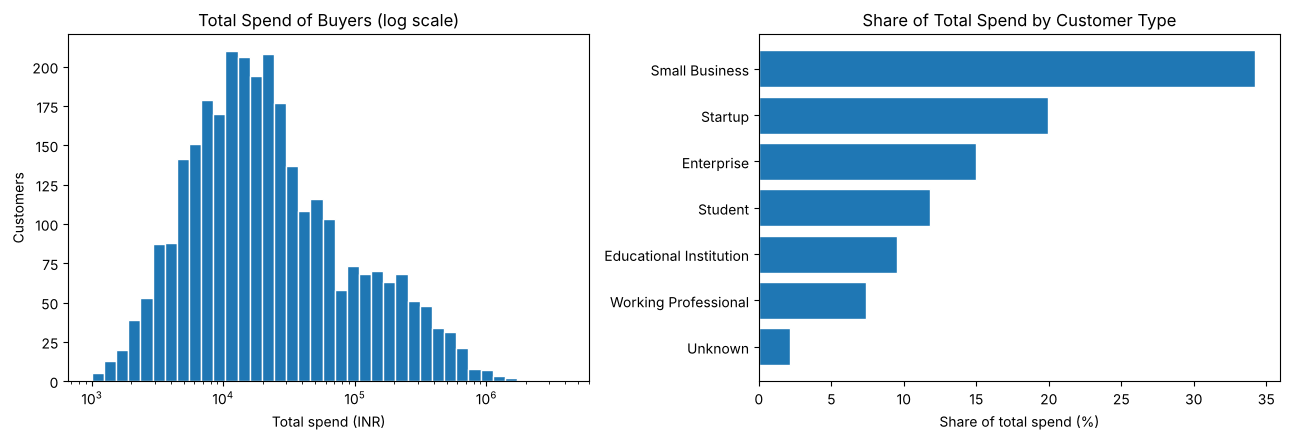

In [23]:
type_spend = customers.groupby("customer_type")["total_spend_inr"].sum().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(buyers["total_spend_inr"], bins=np.logspace(np.log10(buyers["total_spend_inr"].min()), np.log10(buyers["total_spend_inr"].max()), 40), edgecolor="white")
axes[0].set_xscale("log")
axes[0].set_title("Total Spend of Buyers (log scale)")
axes[0].set_xlabel("Total spend (INR)")
axes[0].set_ylabel("Customers")

axes[1].barh(type_spend.index, type_spend / type_spend.sum() * 100, edgecolor="white")
axes[1].set_title("Share of Total Spend by Customer Type")
axes[1].set_xlabel("Share of total spend (%)")

plt.tight_layout()
plt.show()

Half of all spending comes from the top 205 customers (4.1% of customers)


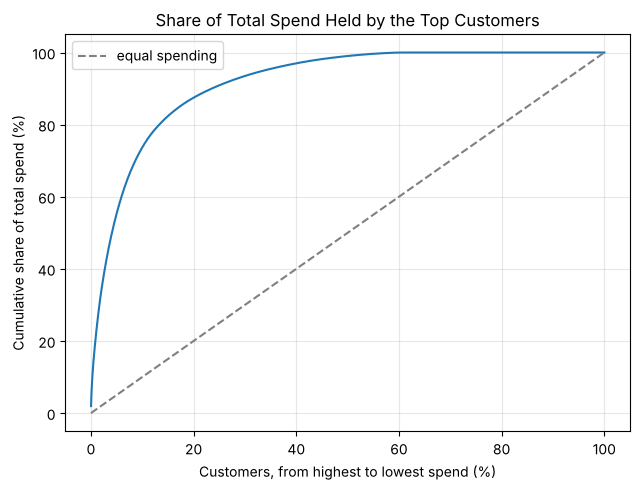

,share of total spend (%)
Top 5% of customers,55.3
Top 10% of customers,73.7
Top 20% of customers,87.5
Top 50% of customers,99.0


In [24]:
ordered = customers["total_spend_inr"].sort_values(ascending=False).to_numpy()
cumulative_share = ordered.cumsum() / ordered.sum()

concentration = pd.Series({
    f"Top {pct}% of customers": cumulative_share[int(len(ordered) * pct / 100) - 1] * 100 for pct in (5, 10, 20, 50)
}).round(1)
customers_for_half = (cumulative_share < 0.5).sum() + 1
print(f"Half of all spending comes from the top {customers_for_half} customers ({customers_for_half / len(ordered) * 100:.1f}% of customers)")

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot(np.arange(1, len(ordered) + 1) / len(ordered) * 100, cumulative_share * 100)
ax.plot([0, 100], [0, 100], linestyle="--", color="grey", label="equal spending")
ax.set_title("Share of Total Spend Held by the Top Customers")
ax.set_xlabel("Customers, from highest to lowest spend (%)")
ax.set_ylabel("Cumulative share of total spend (%)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

concentration.to_frame("share of total spend (%)")

In [25]:
by_interest = customers.groupby("primary_interest").agg(
    customers=("customer_id", "count"), buyers_pct=("is_buyer", "mean"), total_spend_inr=("total_spend_inr", "sum"),
)
by_interest["buyers_pct"] = by_interest["buyers_pct"] * 100
by_interest["avg_spend_per_buyer_inr"] = buyers.groupby("primary_interest")["total_spend_inr"].mean()
by_interest["share_of_total_spend_pct"] = by_interest["total_spend_inr"] / by_interest["total_spend_inr"].sum() * 100
by_interest.round(1).sort_values("total_spend_inr", ascending=False)

,customers,buyers_pct,total_spend_inr,avg_spend_per_buyer_inr,share_of_total_spend_pct
primary_interest,,,,,
IT Services,1037,62.4,98971900,152970.5,48.0
Digital Services,1065,54.0,64098500,111475.7,31.1
Training Programs,1519,61.8,23612200,25146.1,11.4
Internships,1282,61.9,16561800,20885.0,8.0
Unknown,97,60.8,3024400,51261.0,1.5


**Observation:** only 60% of customers have bought anything, and spending is extremely uneven. The average customer spent INR 41,254, but the median customer only INR 5,900, and the average buyer spent INR 68,460. The top 5% of customers account for 55% of all spending, the top 10% for 74%, and half of the INR 206.3 million total comes from just 205 customers (4.1%). The business customer types are 35% of customers but 79% of spending (Small Business alone is 34%), while students and working professionals are 63% of customers but 19% of spending. By interest, IT Services and Digital Services are 42% of customers but 79% of spending (an average of INR 153K and INR 111K per buyer, against INR 25K for Training Programs and INR 21K for Internships), even though the share of customers who buy is similar for every interest (54% to 62%). Customers differ more in how much they spend than in whether they buy, and the average hides this, so any segmentation that uses spending has to handle the skew, for example with a log transform.

**Inquiries, support, and satisfaction**

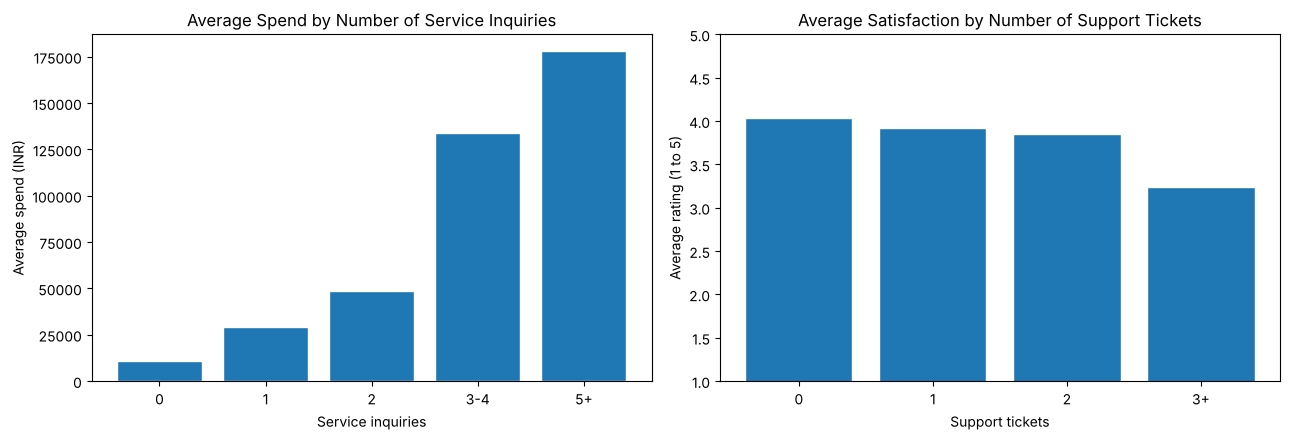

,customers,avg_visits,buyers_pct,avg_spend_inr
inquiry_band,,,,
0,2834,9.3,51.3,11026.5
1,1001,11.1,62.9,28950.1
2,380,12.2,71.1,48876.3
3-4,278,9.3,85.6,133622.3
5+,507,7.5,82.8,178146.9


,customers,survey_responses,avg_satisfaction
ticket_band,,,
0,3286,1706,4.03
1,1001,607,3.92
2,359,197,3.85
3+,354,224,3.24


In [26]:
customers["inquiry_band"] = pd.cut(customers["service_inquiries"], bins=[-1, 0, 1, 2, 4, np.inf], labels=["0", "1", "2", "3-4", "5+"])
customers["ticket_band"] = pd.cut(customers["support_tickets"], bins=[-1, 0, 1, 2, np.inf], labels=["0", "1", "2", "3+"])

by_inquiries = customers.groupby("inquiry_band", observed=True).agg(
    customers=("customer_id", "count"), avg_visits=("website_visits", "mean"), buyers_pct=("is_buyer", "mean"), avg_spend_inr=("total_spend_inr", "mean"),
)
by_inquiries["buyers_pct"] = by_inquiries["buyers_pct"] * 100

by_tickets = customers.groupby("ticket_band", observed=True).agg(
    customers=("customer_id", "count"), survey_responses=("satisfaction_rating", "count"), avg_satisfaction=("satisfaction_rating", "mean"),
)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(by_inquiries.index.astype(str), by_inquiries["avg_spend_inr"], edgecolor="white")
axes[0].set_title("Average Spend by Number of Service Inquiries")
axes[0].set_xlabel("Service inquiries")
axes[0].set_ylabel("Average spend (INR)")
axes[1].bar(by_tickets.index.astype(str), by_tickets["avg_satisfaction"].astype(float), edgecolor="white")
axes[1].set_title("Average Satisfaction by Number of Support Tickets")
axes[1].set_xlabel("Support tickets")
axes[1].set_ylabel("Average rating (1 to 5)")
axes[1].set_ylim(1, 5)
plt.tight_layout()
plt.show()

display(by_inquiries.round(1))
by_tickets.round(2)

**How the measures relate to each other**

Spending is skewed, so the correlation uses the rank-based Spearman method, which is not
distorted by a few very large values.

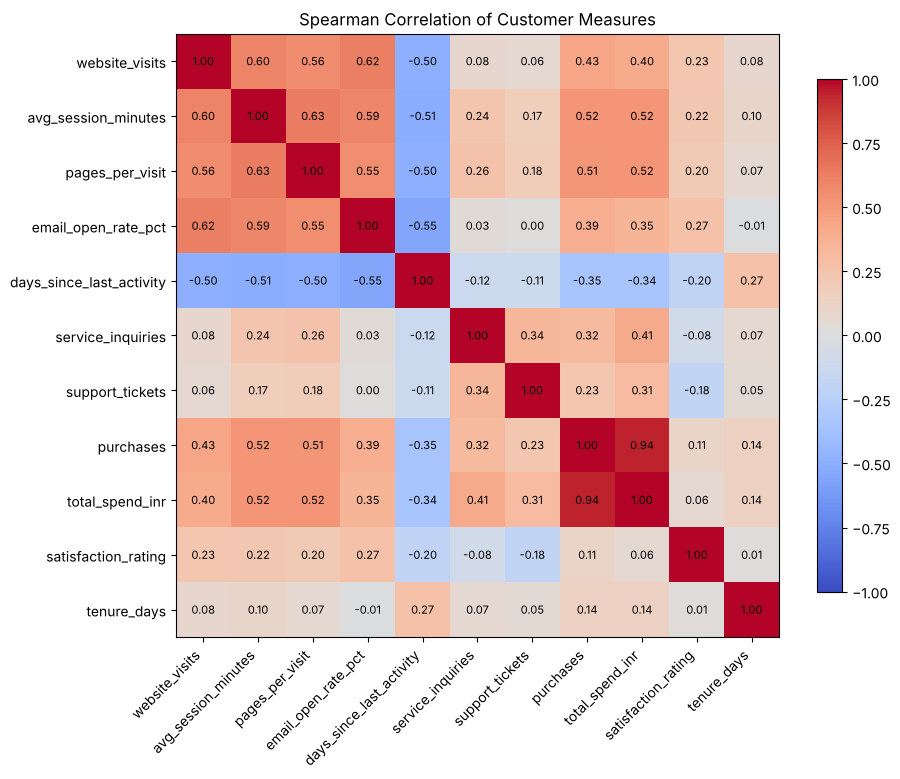

In [27]:
numeric_columns = ["website_visits", "avg_session_minutes", "pages_per_visit", "email_open_rate_pct", "days_since_last_activity",
                   "service_inquiries", "support_tickets", "purchases", "total_spend_inr", "satisfaction_rating", "tenure_days"]
corr = customers[numeric_columns].astype(float).corr(method="spearman").round(2)

fig, ax = plt.subplots(figsize=(9.5, 8))
image = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)))
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Spearman Correlation of Customer Measures")
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

In [28]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)
pairs.head(8).to_frame("spearman_r")

spearman_r
purchases           total_spend_inr                 0.94
avg_session_minutes pages_per_visit                 0.63
website_visits      email_open_rate_pct             0.62
                    avg_session_minutes             0.60
avg_session_minutes email_open_rate_pct             0.59
website_visits      pages_per_visit                 0.56
pages_per_visit     email_open_rate_pct             0.55
email_open_rate_pct days_since_last_activity       -0.55

**Observation:** customers who engage on one measure tend to engage on the others. The strongest links among the engagement measures are 0.55 to 0.63 (session length with pages per visit, visits with email opens, and visits with session length), and customers who open more emails were active more recently (-0.55 with days since last activity). Spending is related most to session length and pages per visit (0.52 each), then to the number of inquiries (0.41), website visits (0.40), email opens (0.35), and how recently the customer was active (-0.34), but every link is moderate, so no single measure predicts spending well. The only very strong link is between purchases and spending (0.94), which is expected because spending is built from purchases, and a reminder to avoid using both as separate clustering features. Customers with 5 or more inquiries spend INR 178K on average against INR 11K for customers with none, and 83% of them have bought against 51%. Support tickets lower satisfaction (an average rating of 4.03 with no tickets against 3.24 with 3 or more) and go together with service inquiries (0.34).

**Do natural groups appear?**

Before using any clustering method, a quick look at two pairs of measures shows whether the
customers form separate groups or one continuous cloud.

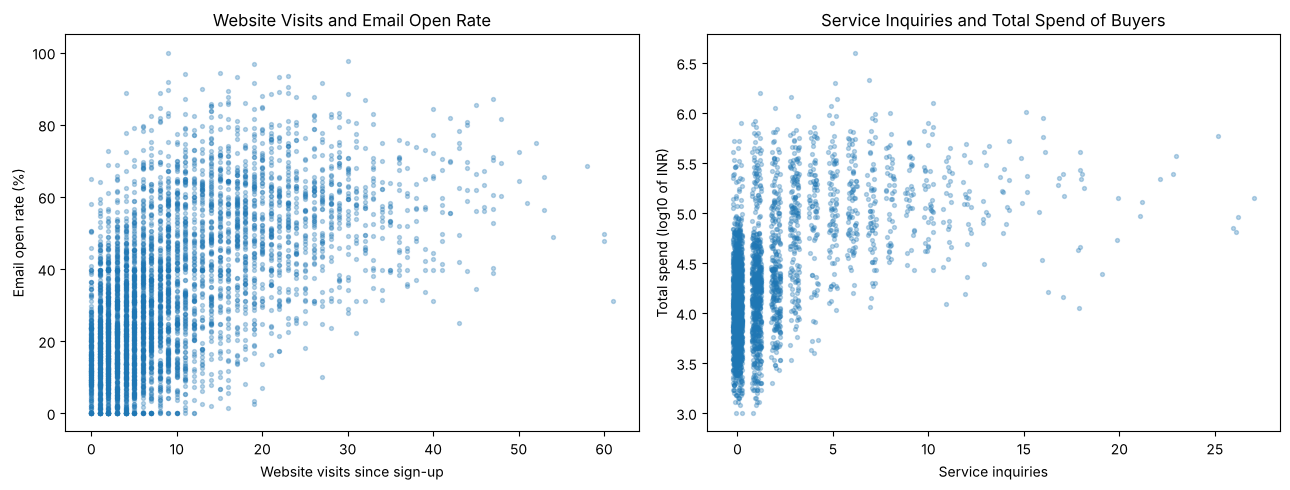

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(customers["website_visits"], customers["email_open_rate_pct"], s=8, alpha=0.3)
axes[0].set_title("Website Visits and Email Open Rate")
axes[0].set_xlabel("Website visits since sign-up")
axes[0].set_ylabel("Email open rate (%)")

jitter = rng.uniform(-0.25, 0.25, len(buyers))
axes[1].scatter(buyers["service_inquiries"] + jitter, np.log10(buyers["total_spend_inr"]), s=8, alpha=0.3)
axes[1].set_title("Service Inquiries and Total Spend of Buyers")
axes[1].set_xlabel("Service inquiries")
axes[1].set_ylabel("Total spend (log10 of INR)")

plt.tight_layout()
plt.show()

**Checking the pandas results with SQL**

The spending summary by customer type is repeated in SQL with `sqlite3` to confirm that it
matches the pandas result.

In [30]:
connection = sqlite3.connect(":memory:")
for_sql = customers.drop(columns=["signup_month", "inquiry_band", "ticket_band"]).copy()
for_sql["signup_date"] = for_sql["signup_date"].dt.strftime("%Y-%m-%d")
for_sql["satisfaction_rating"] = for_sql["satisfaction_rating"].astype(float)
for_sql.to_sql("customers", connection, index=False)

sql_result = pd.read_sql_query("""
    SELECT customer_type,
           COUNT(*) AS customers,
           ROUND(AVG(total_spend_inr), 1) AS avg_spend_inr,
           ROUND(SUM(total_spend_inr) * 100.0 / (SELECT SUM(total_spend_inr) FROM customers), 1) AS share_of_spend_pct
    FROM customers
    GROUP BY customer_type
    ORDER BY avg_spend_inr DESC
""", connection).set_index("customer_type")

pandas_result = customers.groupby("customer_type").agg(customers=("customer_id", "count"), avg_spend_inr=("total_spend_inr", "mean"))
pandas_result["share_of_spend_pct"] = customers.groupby("customer_type")["total_spend_inr"].sum() / customers["total_spend_inr"].sum() * 100
pandas_result = pandas_result.round(1).loc[sql_result.index]

print("SQL result matches pandas:", bool(np.allclose(sql_result.to_numpy(), pandas_result.to_numpy())))
sql_result

SQL result matches pandas: True


,customers,avg_spend_inr,share_of_spend_pct
customer_type,,,
Enterprise,256,120957.4,15.0
Small Business,694,101750.1,34.2
Educational Institution,248,78990.3,9.5
Startup,537,76570.2,19.9
Unknown,119,37009.2,2.1
Working Professional,1202,12654.1,7.4
Student,1944,12534.5,11.8


**Observation:** neither pair of measures separates the customers into clear groups. Visits and email opens rise together, but the points form one dense cloud with a heavy concentration at low values and a long tail toward high values, with no empty gaps between groups. Among buyers, those with 0 or 1 inquiries have a median spend of INR 12,600 and 90% of them spent less than INR 47,500, while those with 3 or more inquiries have a median of INR 113,800, which hints at a service-focused group but does not separate it cleanly because the ranges overlap. So groups, if they exist, overlap and only show up when several measures are used together, which is what K-Means will do on Day 41. Because the measures have very different scales (spending reaches millions while open rates stop at 100) and are skewed, they will have to be standardized, and the skewed ones transformed, first. The SQL query gives the same customer counts, average spend, and share of spend for every customer type as pandas.

## Outcome

This notebook started the Customer Segmentation & Service Recommendation System project. It created a simulated customer dataset of 5,000 customers and 16 columns, made it deliberately messy (100 duplicate rows, more than 1,300 missing cells besides the survey, 147 day-first dates, 56 spending values typed as text, inconsistent labels, and impossible or contradictory numbers), and built one specification-driven preprocessing pipeline that turned 5,100 raw rows into 5,000 clean customers. Validation checks and a comparison with the original table confirmed that the cleaned data was correct, and the cleaned table is saved for Day 41. The behavior analysis found that the typical customer engages lightly (6 website visits, a 30% email open rate) while 69% were active in the last 30 days, that Students are the most engaged type and business customers ask the most service inquiries, and that customers from Email and Referral engage and buy the most. Spending is extremely concentrated: the top 10% of customers hold 74% of it, business customers and IT and Digital Services interests account for about 79% of it, and the median customer spent INR 5,900 against an average of INR 41,254. Engagement measures move together, spending is only moderately related to any single measure, and no pair of measures separates the customers into obvious groups, so segmentation needs several standardized measures at once. Because the data is simulated, these findings reflect the assumptions built into it and practice the analysis workflow instead of describing the real customers of Veda Technology. The raw and cleaned tables are saved in `datasets/veda_customers/` for the next three days of the project.